<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=5>
<b>آماده‌سازی داده: خوندن و تمیز کردن</b>
</font></p>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import html
import re
import os
import difflib
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from wordcloud import WordCloud
from gensim.models import Word2Vec
from gensim.models import KeyedVectors

In [2]:
PATH = '.'
OUT = 'outputs'
os.makedirs(OUT, exist_ok=True)

train = pd.read_csv(PATH + r'\train_data.csv', low_memory=False)
products = pd.read_csv(PATH + r'\title_brand.csv')

print('train:', train.shape)
print('products:', products.shape)

train: (838944, 11)
products: (786445, 3)


In [3]:
train.info()
print(train.isna().mean().round(3))

<class 'pandas.DataFrame'>
RangeIndex: 838944 entries, 0 to 838943
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   overall         838944 non-null  int64
 1   vote            191468 non-null  str  
 2   verified        838944 non-null  bool 
 3   reviewTime      838944 non-null  str  
 4   reviewerID      838944 non-null  str  
 5   asin            838944 non-null  str  
 6   style           490613 non-null  str  
 7   reviewerName    838717 non-null  str  
 8   reviewText      838944 non-null  str  
 9   summary         838868 non-null  str  
 10  unixReviewTime  838944 non-null  int64
dtypes: bool(1), int64(2), str(8)
memory usage: 64.8 MB
overall           0.000
vote              0.772
verified          0.000
reviewTime        0.000
reviewerID        0.000
asin              0.000
style             0.415
reviewerName      0.000
reviewText        0.000
summary           0.000
unixReviewTime    0.000
dtype: f

In [4]:
train['vote'] = pd.to_numeric(train['vote'].str.replace(',', '', regex=False)).fillna(0)

train['summary'] = train['summary'].fillna('')

before = len(train)
train = train.drop_duplicates(['reviewerID', 'asin', 'reviewText'])
print('removed reviews:', before - len(train))

products = products.drop_duplicates('asin')
df = train.merge(products, on='asin', how='left', validate='m:1')

df['date'] = pd.to_datetime(df['unixReviewTime'], unit='s')

print('products:', products.shape)
print('df:', df.shape)
print('vote type:', df['vote'].dtype, '| empty:', df['vote'].isna().sum())
print('no brand:', df['brand'].isna().mean().round(4))

removed reviews: 8554
products: (756077, 3)
df: (830390, 14)
vote type: float64 | empty: 0
no brand: 0.0013


In [5]:
df['title'] = df['title'].map(html.unescape, na_action='ignore')
df['brand'] = df['brand'].map(html.unescape, na_action='ignore')

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
vote رو عدد کردیم و خالیاش که یعنی کمتر از 2 رای رو 0 گذاشتیم.<br>
8554 نظر تکراری حذف شد و عنوان و برند هم اضافه و تمیز شد.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=5>
<b>سوال 1: توزیع امتیازها</b>
</font></p>

          count  share
overall               
1         82225  0.099
2         56274  0.068
3         80444  0.097
4        155110  0.187
5        456337  0.550
total: 830390
always predict the biggest class: 0.5495


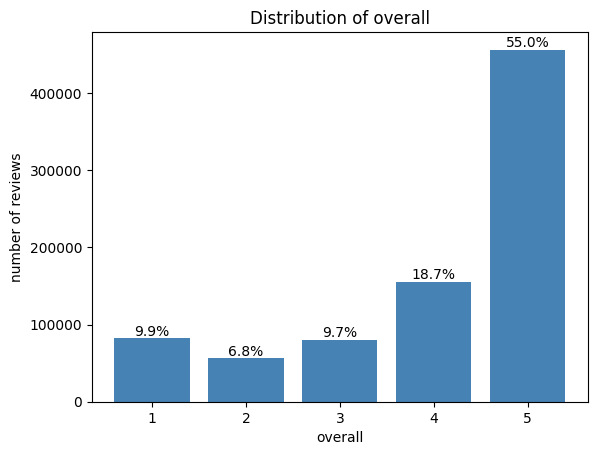

In [6]:
counts = df['overall'].value_counts().sort_index()
shares = df['overall'].value_counts(normalize=True).sort_index()

print(pd.DataFrame({'count': counts, 'share': shares.round(3)}))
print('total:', counts.sum())
print('always predict the biggest class:', round(shares.max(), 4))

bars = plt.bar(counts.index, counts.values, color='steelblue')
plt.bar_label(bars, labels=[f'{s:.1%}' for s in shares])
plt.title('Distribution of overall')
plt.xlabel('overall')
plt.ylabel('number of reviews')
plt.show()

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
ترین متوازن نیست و 55 درصد نظرا 5 هستن. ولی سه تا نشونه میگه تست متوازنه و از هر امتیاز حدود 20 درصد داره: مدل رو تست خیلی کمتر از ولیدیشن 5 میگه و یه تخمین آماری از روی اشتباهای مدل هم همینو میگه و تست هم دقیقا 20 هزار تاست. هنوز رو خود تست امتحان نشده ولی اگه اینطور باشه خط پایه حدود 20 درصده نه 55 پس آره باید کاری کرد.<br>
راه‌حلمون اصلاح prior هست یعنی احتمال هر امتیاز رو تقسیم بر سهمش تو ترین می‌کنیم که مدل کمتر سمت 5 بره. class_weight رو هم امتحان کردیم ولی این بهتر جواب داد و TF-IDF رو ولیدیشن متوازن از 52 به 58 درصد رسید. مدل رو هم با میانگین ریکال 5 تا امتیاز می‌سنجیم. جزئیاتش تو بخش 3 هست.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=5>
<b>سوال 2: ابر کلمات</b>
</font></p>

In [7]:
TAG = re.compile(r'<[^>]+>|https?://\S+|www\.\S+')
WORD = re.compile(r"[a-z]+(?:'[a-z]+)?")

def tokens(text):
    text = html.unescape(text)
    text = TAG.sub(' ', text)
    text = text.lower().replace('\u2019', "'")
    return WORD.findall(text)

df['sentiment'] = df['overall'].map({1: 'negative', 2: 'negative', 3: 'neutral', 4: 'positive', 5: 'positive'})

counts = {}
for name, group in df.groupby('sentiment'):
    c = Counter()
    for text in group['reviewText']:
        c.update(tokens(text))
    counts[name] = c

print(df['sentiment'].value_counts())
for name, c in counts.items():
    print(name, c.most_common(15))

sentiment
positive    611447
negative    138499
neutral      80444
Name: count, dtype: int64
negative [('the', 832353), ('i', 483826), ('to', 452275), ('and', 399809), ('it', 392863), ('a', 376446), ('is', 227384), ('this', 224764), ('of', 214651), ('for', 177601), ('not', 162684), ('in', 157065), ('that', 156038), ('my', 152784), ('on', 150038)]
neutral [('the', 567021), ('to', 289584), ('i', 285911), ('a', 252779), ('it', 244466), ('and', 238135), ('is', 168844), ('of', 135121), ('for', 129117), ('this', 122430), ('that', 106523), ('in', 102937), ('but', 101391), ('on', 95687), ('my', 95298)]
positive [('the', 3567578), ('i', 2079775), ('and', 1961474), ('to', 1909843), ('a', 1852876), ('it', 1507416), ('is', 1133971), ('this', 984920), ('for', 970120), ('of', 931077), ('my', 849287), ('in', 750514), ('with', 740752), ('that', 692077), ('on', 650996)]


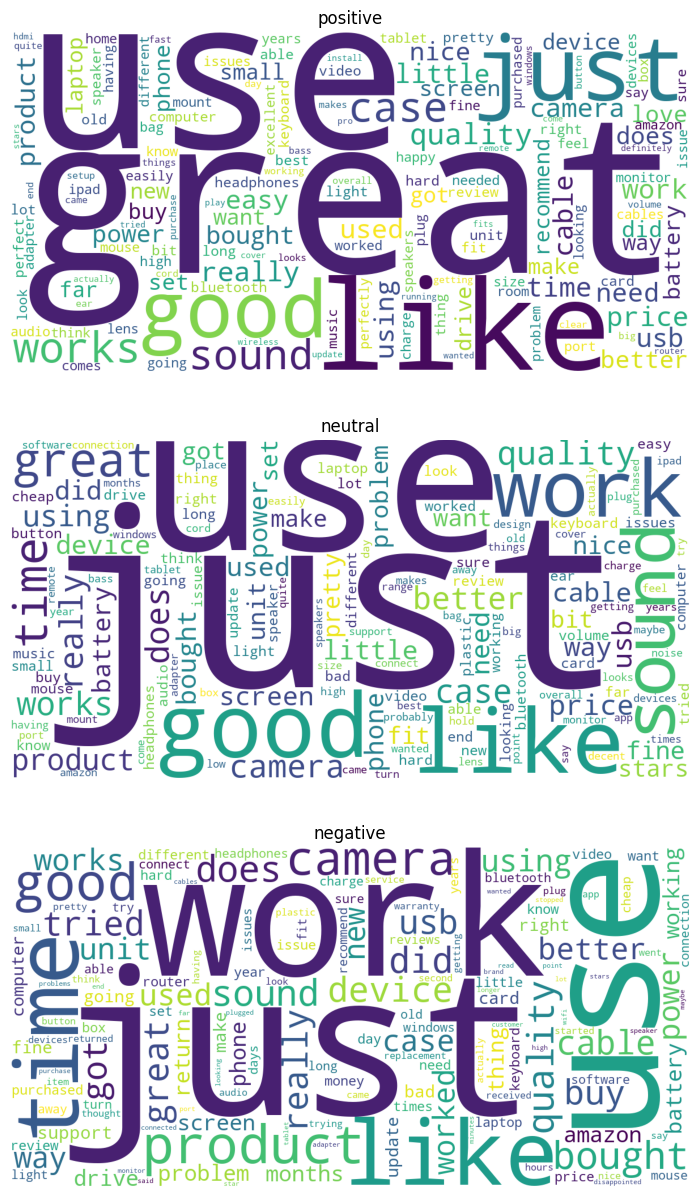

positive [('great', 283868), ('use', 261093), ('like', 223269), ('just', 223017), ('good', 217886), ('works', 156086), ('case', 146401), ('sound', 145859), ('quality', 144748), ('really', 135501), ('cable', 128228), ('price', 127348), ('time', 126117), ('work', 123930), ('using', 120966), ('camera', 119501), ('product', 119047), ('easy', 117514), ('little', 115320), ('usb', 113548)]
neutral [('just', 35355), ('use', 35238), ('good', 32207), ('like', 32207), ('work', 25796), ('sound', 21432), ('great', 21210), ('time', 20161), ('quality', 19533), ('case', 18973), ('does', 18917), ('works', 18837), ('really', 18665), ('camera', 18197), ('better', 17736), ('using', 15750), ('product', 15542), ('price', 14487), ('usb', 13335), ('little', 13029)]
negative [('just', 57126), ('work', 50659), ('use', 46083), ('like', 40368), ('time', 39022), ('product', 36441), ('good', 34050), ('camera', 28105), ('bought', 27347), ('quality', 26070), ('does', 25529), ('sound', 25500), ('did', 25042), ('great'

In [8]:
def clean_counts(c):
    return {w: n for w, n in c.items()
            if w not in ENGLISH_STOP_WORDS and len(w) > 2 and "'" not in w}

clean = {name: clean_counts(c) for name, c in counts.items()}

fig, ax = plt.subplots(3, 1, figsize=(10, 15))

for a, name in zip(ax, ['positive', 'neutral', 'negative']):
    wc = WordCloud(width=1200, height=600, background_color='white',max_words=150, random_state=42).generate_from_frequencies(clean[name])
    a.imshow(wc)
    a.set_title(name)
    a.axis('off')

plt.show()

for name in ['positive', 'neutral', 'negative']:
    print(name, Counter(clean[name]).most_common(20))

In [9]:
pos_top = {w for w, n in Counter(clean['positive']).most_common(50)}
neg_top = {w for w, n in Counter(clean['negative']).most_common(50)}

shared = pos_top & neg_top

print('shared:', len(shared), sorted(shared))
print('only positive:', sorted(pos_top - neg_top))
print('only negative:', sorted(neg_top - pos_top))
print('jaccard:', round(len(shared) / len(pos_top | neg_top), 3))

shared: 34 ['battery', 'better', 'bought', 'buy', 'cable', 'camera', 'case', 'device', 'did', 'does', 'drive', 'good', 'got', 'great', 'just', 'like', 'make', 'new', 'phone', 'power', 'product', 'quality', 'really', 'screen', 'sound', 'thing', 'time', 'usb', 'use', 'used', 'using', 'way', 'work', 'works']
only positive: ['bit', 'easy', 'far', 'fit', 'headphones', 'laptop', 'little', 'love', 'need', 'nice', 'price', 'recommend', 'review', 'set', 'small', 'want']
only negative: ['amazon', 'bad', 'card', 'computer', 'fine', 'going', 'months', 'problem', 'return', 'right', 'support', 'tried', 'unit', 'update', 'worked', 'working']
jaccard: 0.515


positive ['pleasantly', 'loves', 'exceeded', 'hesitate', 'compliments', 'highly', 'unbiased', 'pleased', 'amazed', 'bonus', 'skeptical', 'penny', 'opinions', 'beast', 'loving', 'charm', 'stunning', 'beat', 'zippered', 'versatility', 'steal', 'versatile', 'champ', 'organized', 'portraits']
neutral ['okay', 'disappointing', 'annoying', 'unfortunately', 'hoping', 'frustrating', 'biggest', 'stars', 'uncomfortable', 'rating', 'guess', 'decent', 'description', 'pain', 'returning', 'flimsy', 'weak', 'difficult', 'scroll', 'lack', 'starts', 'major', 'ended', 'somewhat', 'maybe']
negative ['garbage', 'waste', 'junk', 'unacceptable', 'trash', 'worthless', 'refund', 'rma', 'unreliable', 'worst', 'returning', 'wasted', 'unusable', 'useless', 'horrible', 'return', 'crap', 'defective', 'policy', 'terrible', 'nope', 'returned', 'poorly', 'beware', 'joke']


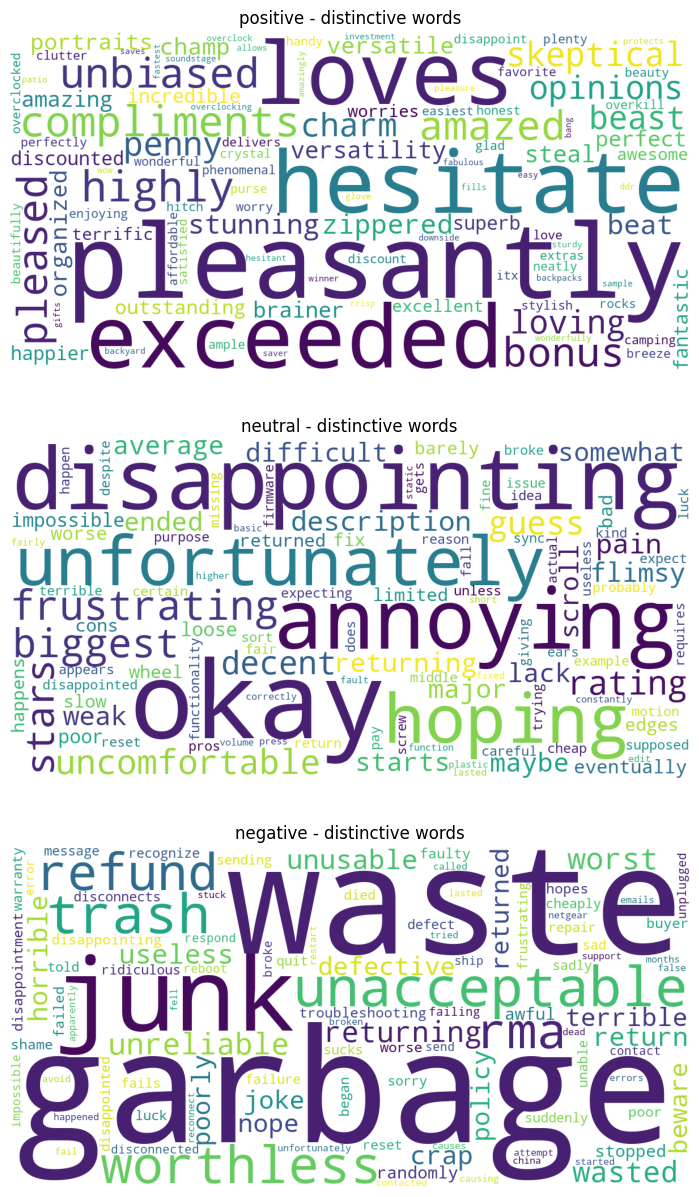

In [10]:
total = {name: sum(c.values()) for name, c in counts.items()}

def distinct(name, min_count=1000):
    others = [n for n in clean if n != name]
    other_total = sum(total[n] for n in others)
    scores = {}
    for w, n in clean[name].items():
        if n >= min_count:
            other_n = sum(clean[o].get(w, 0) for o in others)
            scores[w] = (n / total[name]) / ((other_n + 1) / other_total)
    return scores

fig, ax = plt.subplots(3, 1, figsize=(10, 15))

for a, name in zip(ax, ['positive', 'neutral', 'negative']):
    d = distinct(name)
    wc = WordCloud(width=1200, height=600, background_color='white',max_words=100, random_state=42).generate_from_frequencies(d)
    a.imshow(wc)
    a.set_title(name + ' - distinctive words')
    a.axis('off')
    print(name, [w for w, s in Counter(d).most_common(25)])

plt.show()

In [11]:
print('warranty score in negative:', round(distinct('negative')['warranty'], 1))

warranty score in negative: 4.2


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
ابرهای پرتکرار شبیه همن و jaccard مثبت و منفی 0.515 شد چون بیشتر اسم محصول و کلمات عمومی مشترکن.<br>
تو ابر متمایز فرقشون معلومه: مثبت pleasantly و exceeded و منفی garbage و waste.<br>
great و good تو منفی هم زیادن چون مثلا میگن not good یا اولش عالی بود بعد خراب شد.<br>
warranty تو منفی حدود 4 برابر بقیه میاد.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=5>
<b>سوال 3: 10 نفر با بیشترین مجموع رای</b>
</font></p>

In [12]:
print(df['reviewerName'].value_counts().head(3))
print(df.groupby('reviewerName')['reviewerID'].nunique().sort_values(ascending=False).head(3))

top_voters = df.groupby('reviewerID').agg(name=('reviewerName', 'first'), total_vote=('vote', 'sum')).sort_values('total_vote', ascending=False).head(10)
print(top_voters)

reviewerName
Amazon Customer    24572
Kindle Customer     2434
Mike                1754
Name: count, dtype: int64
reviewerName
Amazon Customer    10691
Kindle Customer     1251
Mike                 675
Name: reviewerID, dtype: int64
                         name  total_vote
reviewerID                               
A25GROL6KJV3QG   Benson Leung      4572.0
A3KJ0DF3LTNJ6X     Voltron00x      3181.0
A2IK776FY6MEMG        Obi Wan      3150.0
A1KPFZCS71QKW5         nycebo      2978.0
AMYCUX8EWEUVV        Mayra S.      2631.0
ADLVFFE4VBT8          Cthulhu      2607.0
A1GHPJB2N0D0RL    Chris Upton      2167.0
AW7UMXXJKFSNS        Sally B.      1912.0
A33AN9NP6574M2             DJ      1867.0
A2VQ0V1TWXF3U7  Mark A. Baker      1820.0


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
اسم یکتا نیست پس با reviewerID گروه کردیم. نفر اول Benson Leung با 4572 رای هست.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=5>
<b>سوال 4: طول متن</b>
</font></p>

       text_len  word_len
count  830390.0  830390.0
mean      626.0     115.0
std       685.0     124.0
min       200.0       1.0
50%       409.0      76.0
90%      1219.0     224.0
95%      1737.0     317.0
99%      3403.0     614.0
max     29146.0    5144.0


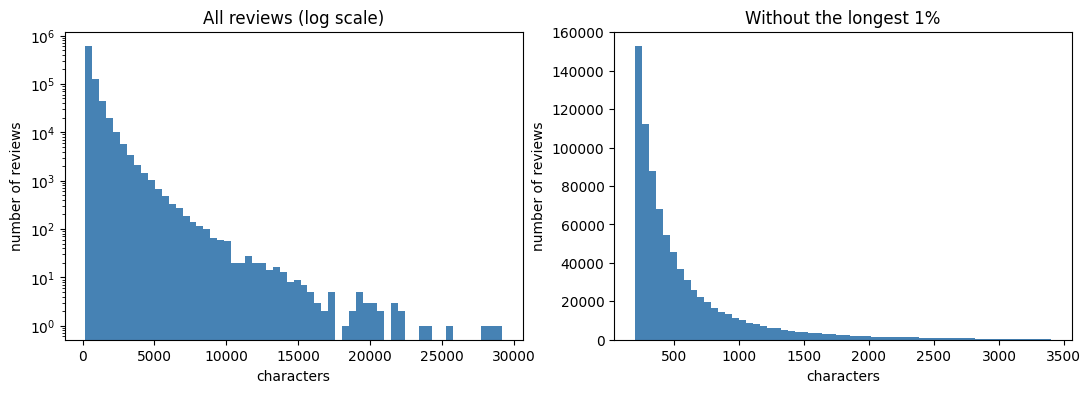

In [13]:
df['text_len'] = df['reviewText'].str.len()
df['word_len'] = df['reviewText'].str.split().str.len()

print(df[['text_len', 'word_len']].describe(percentiles=[.5, .9, .95, .99]).round(0))

limit = df['text_len'].quantile(.99)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].hist(df['text_len'], bins=60, color='steelblue')
ax[0].set_title('All reviews (log scale)')
ax[0].set_yscale('log')

ax[1].hist(df.loc[df['text_len'] <= limit, 'text_len'], bins=60, color='steelblue')
ax[1].set_title('Without the longest 1%')

for a in ax:
    a.set_xlabel('characters')
    a.set_ylabel('number of reviews')

plt.show()

In [14]:
short = df[df['word_len'] <= 3]

print('count:', len(short))
print(short['reviewText'].str[:100].head(10).to_list())

count: 4
['https://www.amazon.com/gp/r.html?C=2B4D8XO3SVQMT&K=1EY0SC2IUR0I6&M=urn:rtn:msg:201709120443067ad5b27', 'https://www.amazon.com/s/ref=w_bl_sl_s_ap_web_7141123011?ie=UTF8&node=7141123011&field-brandtextbin=', 'Worksgreatatasastylesorapen.myonlycomplaintistiwearpocketsirtsalotandtheyaretoolongtocipinpocketgood', 'Boughtthiscameraasbirthdaygifttomysister,shelovesitsomuchtocheckherpuppywhenawayfromhome. Crystalpic']


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
نمودار چوله‌ست و چند نظر خیلی بلند میانگین رو از میانه بیشتر کردن.<br>
حد پایین لازم نیست چون کمترین طول 200 هست. برای حد بالا حدود 1700 کاراکتر (صدک 95) خوبه که میشه حدود 320 کلمه.<br>
نمودار اول رو لگاریتمی کردیم که ستونای کم هم دیده بشن.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=5>
<b>سوال 5: 10 محصول با بیشترین امتیاز 5</b>
</font></p>

In [15]:
five = df[df['overall'] == 5]

top_products = five.groupby('asin').agg(brand=('brand', 'first'), title=('title', 'first'), five_count=('overall', 'size')).sort_values('five_count', ascending=False).head(10)

top_products['all_reviews'] = df['asin'].value_counts().reindex(top_products.index)
top_products['five_share'] = (top_products['five_count'] / top_products['all_reviews']).round(3)

pd.set_option('display.max_colwidth', 60)
display(top_products)

,brand,title,five_count,all_reviews,five_share
asin,,,,,
B010OYASRG,Cambridge Soundworks,OontZ Angle 3 Enhanced Stereo Edition IPX5 Splashproof P...,1163,1852,0.628
B00L0YLRUW,NETGEAR,NETGEAR N300 WiFi Range Extender (EX2700),659,1205,0.547
B01DA0YCNC,Roku,Roku Streaming Stick (3600R) - HD Streaming Player with ...,600,996,0.602
B0043T7FXE,Logitech,Logitech M570 Wireless Trackball Mouse – Ergonomic Desig...,552,856,0.645
B00OBRE5UE,Samsung,Samsung 850 EVO 500GB 2.5-Inch SATA III Internal SSD (MZ...,529,624,0.848
B00S9SGNNS,Asus,ASUS Tri-Band Gigabit (AC3200) WiFi Router (Up to 3167 M...,442,857,0.516
B00P7EVST6,"Arlo Technologies, Inc",Arlo - Wireless Home Security Camera System | Indoor/Out...,433,1115,0.388
B00OAJ412U,Samsung,Samsung 850 EVO 250GB 2.5-Inch SATA III Internal SSD (MZ...,431,497,0.867
B00DIF2BO2,Cheetah,Cheetah Mounts APFMSB TV Wall Mount Bracket for 20-55” T...,428,737,0.581


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
بیشترین امتیاز 5 یعنی بهترین محصول نیست: Arlo با 433 تا 38.8 درصده و سامسونگ 250 گیگ با 431 تا 86.7 درصد.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=5>
<b>سوال 6: میانگین امتیاز 10 برند پرنظر</b>
</font></p>

In [16]:
brand_counts = df['brand'].value_counts()
main_name = pd.Series(brand_counts.index, index=brand_counts.index.str.strip().str.lower())
main_name = main_name[~main_name.index.duplicated()]
df['brand'] = df['brand'].str.strip().str.lower().map(main_name)

top_brands = df.groupby('brand')['overall'].agg(n_reviews='size', mean_overall='mean').sort_values('n_reviews', ascending=False).head(10).sort_values('mean_overall', ascending=False).round(3)

display(top_brands)
print('mean of all reviews:', round(df['overall'].mean(), 3))

,n_reviews,mean_overall
brand,,
Anker,9859,4.244
AmazonBasics,13183,4.200
Sabrent,7306,4.028
SanDisk,8346,3.957
Logitech,16827,3.951
Samsung,15399,3.941
TP-LINK,9773,3.929
Sony,11598,3.918
Asus,11880,3.855


mean of all reviews: 4.02


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
اسم برندا رو یه‌دست کردیم چون مثلا HP و hp جدا بودن ولی ده تای اول عوض نشد.<br>
میانگین کل 4.02 هست. Anker و AmazonBasics بالاترن و Logitech با بیشترین نظر پنجمه پس نظر زیاد یعنی رضایت بیشتر نیست.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=5>
<b>بخش 2: رضایت از گارانتی</b>
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>قدم 1: روش ساده</b>
</font></p>

In [17]:
df['text'] = (df['summary'] + ' . ' + df['reviewText']).str.lower().str.replace('\u2019', "'", regex=False)

base = df['text'].str.contains(r'\b(?:warranty|guarantee)\b', regex=True)

print('reviews found:', base.sum(), '|', round(base.mean() * 100, 2), '%')
print('mean overall, found:', round(df.loc[base, 'overall'].mean(), 3))
print('mean overall, all:', round(df['overall'].mean(), 3))

reviews found: 17238 | 2.08 %
mean overall, found: 3.169
mean overall, all: 4.02


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
با جستجوی دقیق warranty و guarantee تعداد 17238 نظر پیدا شد. میانگینشون 3.17 هست ولی میانگین کل 4.02.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>قدم 2: Word2Vec روی خود نظرها</b>
</font></p>

In [18]:
sentences = [tokens(t) for t in df['text']]

vocab = Counter()
for s in sentences:
    vocab.update(s)

model = Word2Vec(sentences, vector_size=100, window=5, min_count=3, sg=1, workers=6, epochs=3, seed=42)
model.wv.save(PATH + r'\w2v.kv')

print('words in model:', len(model.wv))

for q in ['warranty', 'guarantee']:
    print('\n', q)
    for w, score in model.wv.most_similar(q, topn=30):
        print(f'{w:20} {score:.2f} {vocab[w]}')

words in model: 70006

 warranty
warrantee            0.92 265
warrenty             0.88 129
warranties           0.84 466
waranty              0.79 38
expired              0.79 1115
honored              0.78 263
policy               0.77 2322
honoring             0.77 82
expires              0.76 284
voided               0.76 95
honor                0.76 895
warrantied           0.76 82
squaretrade          0.75 378
asurion              0.75 105
assurant             0.74 94
warantee             0.74 17
honors               0.73 52
smartguard           0.73 34
guaranty             0.72 28
rebate               0.72 700
eligibility          0.71 19
warrantech           0.71 15
lifetime             0.71 3168
trade's              0.71 14
expiration           0.70 172
unconditional        0.70 16
honour               0.68 8
applecare            0.68 50
refunds              0.68 117
rebates              0.67 105

 guarantee
promise              0.74 1420
guaranty             0.74 28
assure  

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
مدل غلطایی مثل warrenty و waranty و شرکتای گارانتی مثل squaretrade رو پیدا کرد.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>قدم 3: مقایسه با GloVe</b>
</font></p>

In [19]:
w2v = KeyedVectors.load(PATH + r'\w2v.kv')
glove = KeyedVectors.load_word2vec_format(PATH + r'\glove.6B.100d.txt', binary=False, no_header=True)

for q in ['warranty', 'guarantee']:
    print(q, '| GloVe:', [w for w, s in glove.most_similar(q, topn=15)])

for w in ['warrantee', 'warrenty', 'waranty', 'squaretrade']:
    print(w, '| in GloVe:', w in glove, '| in our model:', w in w2v)

warranty | GloVe: ['warranties', 'renewals', 'lease', 'powertrain', 'end-user', 'exclusivity', 'redundancy', 'expiration', 'annuity', 'termination', 'leases', 'retainer', 'bios', 'exemption', 'mileage']
guarantee | GloVe: ['guarantees', 'guaranteed', 'ensure', 'guaranteeing', 'assure', 'necessary', 'ensuring', 'insure', 'secure', 'adequate', 'provide', 'sufficient', 'maintain', 'benefit', 'promise']
warrantee | in GloVe: False | in our model: True
warrenty | in GloVe: False | in our model: True
waranty | in GloVe: False | in our model: True
squaretrade | in GloVe: True | in our model: True


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
GloVe غلطا رو نداشت و همسایه‌هاش مالی و ماشینی بودن چون روی ویکی‌پدیا و اخبار آموزش دیده. پس مدل خودمون رو گرفتیم.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>قدم 4: غلطای تایپی با difflib</b>
</font></p>

In [20]:
if 'vocab' not in globals():
    vocab = Counter()
    for t in df['text']:
        vocab.update(tokens(t))

words = [w for w, n in vocab.items() if 4 <= len(w) <= 14]

for q in ['warranty', 'warrantee', 'warranties', 'guarantee', 'guaranty']:
    close = difflib.get_close_matches(q, words, n=60, cutoff=0.75)
    print('\n', q, [(w, vocab[w]) for w in close])


 warranty [('warranty', 23356), ('watrranty', 1), ('warrranty', 3), ('warrantys', 1), ('warrantty', 2), ('warrantry', 1), ('warrantly', 6), ('warranity', 1), ('waarranty', 1), ('wrranty', 1), ('warrnty', 1), ('warraty', 5), ('warrany', 9), ('warrant', 460), ('waranty', 38), ("warranty's", 8), ("warranty'd", 1), ('avwarranty', 1), ('watranty', 3), ('warrenty', 129), ('warrants', 142), ('warrabty', 1), ('garranty', 1), ('warray', 1), ('warnty', 1), ('warrantyvon', 2), ('warrantyran', 1), ('warrantying', 3), ('warrantybut', 1), ('warrrenty', 1), ('warrnatny', 1), ('warrently', 4), ('warrantte', 1), ('warrantor', 2), ('warrantee', 265), ('warranted', 258), ('yearwarranty', 1), ('warrent', 4), ('warenty', 7), ('garanty', 1), ('warranting', 11), ('warranties', 466), ('warrantied', 82), ('warrantees', 9), ('warranteed', 7), ('warrantech', 15), ('arrogantly', 1), ('aperrantly', 1), ('warry', 2), ('ranty', 1), ('array', 1475), ('wattanty', 2), ('warrenyt', 1), ('warraned', 1), ('warcraft', 228

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
difflib کلمه‌های هم‌حروف رو میده و غلطای کم‌تکرار رو هم پیدا کرد. چیزایی مثل array و warcraft رو دستی کنار گذاشتیم.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>قدم 5: کلمه‌های مشکوک</b>
</font></p>

In [21]:
def show(word, n=6, seed=1):
    pattern = r'\b' + re.escape(word) + r'\b'
    m = df['text'].str.contains(pattern, regex=True)
    print(f'\n{word}: {m.sum()} reviews | mean overall {df.loc[m, "overall"].mean():.2f}')
    for t in df.loc[m, 'text'].sample(min(n, m.sum()), random_state=seed):
        p = re.search(pattern, t).start()
        print('   ...', t[max(0, p - 60):p + 60].replace('\n', ' '))

for w in ['warrant', 'warranted', 'guaranteed', 'guarantee', 'lifetime', 'policy']:
    show(w)


warrant: 450 reviews | mean overall 3.66
   ... on the hole. that design of use alone is probably enough to warrant buying it over the competition i think. the auto sho
   ... ally does it every other day or so. it was almost enough to warrant a return but i am just going to live with it... the 
   ... sing a secondary set of wonderful in-ear monitors simply to warrant trying out the different brands.  if you're in the m
   ... rks very well.  i enjoy the mouse and do not game enough to warrant a 200 investment in a mouse and keyboard.
   ...  in action or i simply don't buy enough stuff every year to warrant anyone wanting to try to get my opinion. so basicall
   ...  up. there's no notification or interruption on my phone to warrant an accidental pause of audio. and then sometimes my 

warranted: 255 reviews | mean overall 3.87
   ... pealing. i feel that the price of the roost laptop stand is warranted considering the quality, durability, functionality
   ...  doesn't fit at least 

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
warrant و warranted و guaranteed بیشتر معنی دیگه داشتن و lifetime و policy درباره چیزای دیگه بودن پس کنار رفتن.<br>
guarantee رو نگه داشتیم ولی وقتی فعل بود مثل i guarantee you حذف میشه.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>قدم 6: فیلتر نهایی</b>
</font></p>

In [22]:
WAR_WORDS = ['warranty', 'warranties', 'warrantee', 'warrantees', 'warrantied', 'warranteed', "warranty's",'warrantor', 'warrantying', 'guaranty', 'guaranties','warrenty', 'waranty', 'warantee', 'warrentee', 'warentee', 'warenty', 'warraty', 'warrany', 'warrantly','warrnty', 'wrranty', 'warrranty', 'watranty', 'wattanty', 'warrantty', 'warranity', 'warrantry', 'warrantys','watrranty', 'waarranty', 'warrabty', 'warrenties', 'warrentied', 'warreties', 'warrrenty', 'warnty','qarrenty', 'warrenyt', 'warrnatny', 'warrantte', 'garranty', 'garanty','squaretrade', 'square trade', 'asurion', 'assurant', 'smartguard', 'warrantech']
GUA_WORDS = ['guarantee', 'guarantees', 'guarentee', 'guarentees', 'guarrantee', 'gurantee', 'gurantees', 'gaurantee','gaurantees', 'garantee', 'garuntee', 'guarantie', 'guarntee', 'guaratee', 'guaranatee', 'garauntee','garauntees', 'gauruntee', 'guatentee', 'guranteee']

def rx(words):
    return r'\b(?:' + '|'.join(re.escape(w) for w in sorted(words, key=len, reverse=True)) + r')\b'

WAR = rx(WAR_WORDS)
GUA = rx(GUA_WORDS)
BEFORE = r"\b(?:i|we|to|not|no|never|can|cannot|can't|will|won't|doesn't|don't|didn't|couldn't|would|could|might|may|that|it|you|they)\s+$"
AFTER = r"\s+(?:that|it|you|a|an|the|your|this|they|any)\b"

def is_product_guarantee(t):
    for m in re.finditer(GUA, t):
        before = t[max(0, m.start() - 14):m.start()]
        after = t[m.end():m.end() + 8]
        if re.search(BEFORE, before) or re.match(AFTER, after):
            continue
        return True
    return False

war = df['text'].str.contains(WAR, regex=True)
gua = df['text'].str.contains(GUA, regex=True)
only_gua = gua & ~war
kept = df.loc[only_gua, 'text'].map(is_product_guarantee)

df['warranty'] = war
df.loc[kept[kept].index, 'warranty'] = True

print('baseline:', base.sum(), '| new:', df['warranty'].sum(), '| gain:', df['warranty'].sum() - base.sum())
print('guarantee-only reviews:', only_gua.sum(), '| kept:', kept.sum(), '| dropped as verb:', (~kept).sum())
print('mean overall, new:', round(df.loc[df['warranty'], 'overall'].mean(), 3))

baseline: 17238 | new: 17257 | gain: 19
guarantee-only reviews: 1585 | kept: 611 | dropped as verb: 974
mean overall, new: 3.138


In [23]:
print('added (not in baseline):', (df['warranty'] & ~base).sum())
print('removed (baseline but not ours):', (base & ~df['warranty']).sum())

added (not in baseline): 900
removed (baseline but not ours): 881


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
از 1585 نظری که فقط guarantee داشتن 974 تا فعل بودن و حذف شدن.<br>
900 نظر به روش ساده اضافه شد و 881 نظر اشتباه حذف شد. میانگین هم شد 3.14.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>قدم 7: بررسی دستی</b>
</font></p>

In [24]:
POOL = r'\b(?:covered|coverage|replacement|replaced it|rma|manufacturer|refund)\b'

found = df[df['warranty']].sample(50, random_state=1)
pool = df[~df['warranty'] & df['text'].str.contains(POOL, regex=True)]
missed = pool.sample(50, random_state=1)
print('pool size:', len(pool))

def snippet(t, pattern):
    m = re.search(pattern, t)
    p = m.start() if m else 0
    return t[max(0, p - 150):p + 150]

found = found.assign(found=1, snip=found['text'].map(lambda t: snippet(t, WAR + '|' + GUA)))
missed = missed.assign(found=0, snip=missed['text'].map(lambda t: snippet(t, POOL)))

check = pd.concat([found, missed])[['asin', 'overall', 'found', 'snip']]
check['is_warranty'] = ''
if not os.path.exists(OUT + r'\manual_check.csv'):  # keep the labels already filled in
    check.to_csv(OUT + r'\manual_check.csv', index=False, encoding='utf-8-sig')
print('saved', len(check), 'rows')

pool size: 53266
saved 100 rows


In [25]:
check = pd.read_csv(OUT + r'\manual_check.csv')
done = check.dropna(subset=['is_warranty'])

precision = done.loc[done['found'] == 1, 'is_warranty'].mean()
missed_rate = done.loc[done['found'] == 0, 'is_warranty'].mean()

print('checked:', len(done))
print('precision (found and really warranty):', round(precision, 2))
print('missed (not found but warranty):', round(missed_rate, 2))

checked: 100
precision (found and really warranty): 0.98
missed (not found but warranty): 0.2


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
از 50 نظر پیدا شده 49 تا واقعا درباره گارانتی بودن.<br>
از 50 نظری که پیدا نشدن ولی کلمه‌ای مثل replacement داشتن 10 تا گارانتی بودن بدون اینکه اسمش رو بیارن مثلا شرکت یه دونه نو فرستاده بود. این محدودیت روش کلمه‌ایه.<br>
پس حدود 20 درصد اون 53 هزار تا یعنی حدود 10 هزار نظر جا افتادن در برابر 17 هزار تا که پیدا شدن. یعنی روش ما حدود 60 درصد نظرای گارانتی رو پیدا میکنه.
</font></p>

In [26]:
dropped = df.loc[kept[~kept].index]
print('dropped as verb:', len(dropped), '| with "no guarantee":', dropped['text'].str.contains(r'\bno\s+' + GUA, regex=True).sum())

verb = dropped.sample(50, random_state=1)
verb = verb.assign(snip=verb['text'].map(lambda t: snippet(t, GUA)))[['asin', 'overall', 'snip']]
verb['is_warranty'] = ''
if not os.path.exists(OUT + r'\verb_check.csv'):  # keep the labels already filled in
    verb.to_csv(OUT + r'\verb_check.csv', index=False, encoding='utf-8-sig')

verb = pd.read_csv(OUT + r'\verb_check.csv')
print('checked:', len(verb), '| really warranty:', verb['is_warranty'].sum())

dropped as verb: 974 | with "no guarantee": 161
checked: 50 | really warranty: 1


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
974 نظری که فیلتر فعل انداخته بود رو هم چک کردیم. 161 تاش no guarantee دارن ولی بیشترشون یعنی تضمینی نیست که... نه گارانتی محصول.<br>
از 50 نمونه فقط 1 تا درباره گارانتی بود پس فیلتر درست کار میکنه.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>قدم 8: اضافه کردن rma</b>
</font></p>

In [27]:
rma = df['text'].str.contains(r'\brma\b', regex=True) & ~df['warranty']
print('rma reviews not found yet:', rma.sum(), '| mean overall:', round(df.loc[rma, 'overall'].mean(), 3))

rma_check = df[rma].sample(40, random_state=1)
rma_check = rma_check.assign(snip=rma_check['text'].map(lambda t: snippet(t, r'\brma\b')))[['asin', 'overall', 'snip']]
rma_check['is_warranty'] = ''
if not os.path.exists(OUT + r'\rma_check.csv'):  # keep the labels already filled in
    rma_check.to_csv(OUT + r'\rma_check.csv', index=False, encoding='utf-8-sig')

rma_check = pd.read_csv(OUT + r'\rma_check.csv')
print('checked:', len(rma_check), '| really warranty:', round(rma_check['is_warranty'].mean(), 2))

df.loc[rma, 'warranty'] = True
print('final:', df['warranty'].sum(), '| mean overall:', round(df.loc[df['warranty'], 'overall'].mean(), 3))

rma reviews not found yet: 1380 | mean overall: 2.401
checked: 40 | really warranty: 0.85
final: 18637 | mean overall: 3.083


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
rma یعنی مجوز مرجوعی و تو بررسی دستی دیدیم خیلی از نظرای جاافتاده اینو دارن.<br>
1380 نظر rma داشتن ولی پیدا نشده بودن و از 40 نمونه 34 تاش یعنی 85 درصد واقعا گارانتی بودن پس اضافه شدن.<br>
حالا 18637 نظر داریم با میانگین 3.08 و روش حدود 65 درصد نظرای گارانتی رو پیدا میکنه.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>قدم 9: میانگین امتیاز گارانتی هر محصول</b>
</font></p>

In [28]:
w = df[df['warranty']]

table = w.groupby('asin').agg(brand=('brand', 'first'),title=('title', 'first'),n_warranty=('overall', 'size'),mean_warranty=('overall', 'mean'))
table = table.join(df.groupby('asin')['overall'].agg(n_all='size', mean_all='mean'))
table['diff'] = table['mean_warranty'] - table['mean_all']
table = table.round(2).sort_values('n_warranty', ascending=False)

table.to_csv(OUT + r'\warranty_by_product.csv', encoding='utf-8-sig')

print('products with warranty reviews:', len(table))
for k in [3, 5, 10]:
    print(f'products with at least {k}:', (table['n_warranty'] >= k).sum())

big = table[table['n_warranty'] >= 5]
print('mean diff (n >= 5):', round(big['diff'].mean(), 2))

display(big.head(10))
display(big.sort_values('mean_warranty').head(5))
display(big.sort_values('mean_warranty').tail(5))

products with warranty reviews: 9733
products with at least 3: 1549
products with at least 5: 625
products with at least 10: 185
mean diff (n >= 5): -0.83


,brand,title,n_warranty,mean_warranty,n_all,mean_all,diff
asin,,,,,,,
B00IVPU7AO,Samsung,Samsung EVO 64GB 48/MB/s Micro SDXC Memory Card with Ad...,51,1.73,466,3.18,-1.45
B0163CHND0,Microsoft,Microsoft Band 2 - Medium,50,1.68,212,2.79,-1.11
B00DSUTX3O,Western Digital,WD Black 750GB Performance Mobile Hard Disk Drive - 7200...,49,3.96,242,4.24,-0.28
B00LF10KTE,Samsung,Samsung 850 PRO - 1TB - 2.5-Inch SATA III Internal SSD (...,49,4.14,290,4.60,-0.46
B008VQ8IKY,Western Digital,WD Red 8TB NAS Hard Disk Drive - 5400 RPM Class SATA 6 G...,45,3.20,290,4.16,-0.96
B00S9SGNNS,Asus,ASUS Tri-Band Gigabit (AC3200) WiFi Router (Up to 3167 M...,43,2.51,857,3.68,-1.16
B004LB5AZY,Corsair,"CORSAIR CSM Series, CS550M, 550 Watt, 80+ Gold Certified...",43,4.12,252,4.44,-0.32
B013HNYVCE,Western Digital,"WD Blue 6TB PC Hard Drive - 5400 RPM Class, SATA 6 Gb/s,...",34,2.53,232,4.08,-1.55
B0092ML0MY,Corsair,Corsair CX Series 500 Watt 80 Plus Bronze Certified Non-...,33,2.55,235,3.91,-1.36


,brand,title,n_warranty,mean_warranty,n_all,mean_all,diff
asin,,,,,,,
B00WWI9UW2,ViewSonic,ViewSonic VFD820-70 8-Inch Digital Photo Frame (White),5,1.0,17,2.59,-1.59
B019GZ53VU,VIZIO,VIZIO 32 inches 720 p LED TV D32HN-E0 (2016),8,1.0,125,3.66,-2.66
B00NPZG6DW,Parrot,Parrot Zik 2.0 Wireless Noise Cancelling Headphones (Black),5,1.0,27,3.33,-2.33
B008FC8FJ8,ViewSonic,ViewSonic VFD820-50 8-Inch Digital Photo Frame (Black),6,1.0,17,2.53,-1.53
B00O8B7CP8,Pioneer,"Pioneer AVH-X3700BHS DVD Receiver with 6.2-Inch Display,...",5,1.0,11,1.91,-0.91


,brand,title,n_warranty,mean_warranty,n_all,mean_all,diff
asin,,,,,,,
B00EU799O2,Snugg,"Macbook Pro 15 Sleeve, Snugg - Brown Leather Sleeve Case...",5,5.0,17,4.59,0.41
B0002SKHIK,Pelican,Pelican 1510 Case With Foam (Black),5,5.0,114,4.71,0.29
B00RNGOBYK,amFilm,amFilm iPad 9.7 Screen Protector Tempered Glass for Appl...,5,5.0,175,4.47,0.53
B00S7YA5FQ,Cryorig,CRYORIG H7 Tower Cooler For AMD/Intel CPU's,5,5.0,149,4.52,0.48
B015PC7R6W,Syncwire,Syncwire Lightning to USB A Cable - Nylon Braided [Apple...,7,5.0,20,4.60,0.40


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
625 محصول حداقل 5 نظر گارانتی دارن و امتیاز گارانتی‌شون به طور میانگین 0.83 کمتر از امتیاز کل همون محصوله.<br>
یعنی وقتی کسی از گارانتی حرف میزنه معمولا محصول خراب شده. جدول کامل تو outputs/warranty_by_product.csv ذخیره شد.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=5>
<b>تحلیل‌های اضافه</b>
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>تحلیل 1: رای مفید بر اساس امتیاز</b>
</font></p>

         n_reviews  mean_vote  share_with_vote
overall                                       
1            82225      2.276            0.329
2            56274      1.351            0.229
3            80444      1.549            0.222
4           155110      1.586            0.213
5           456337      1.762            0.218


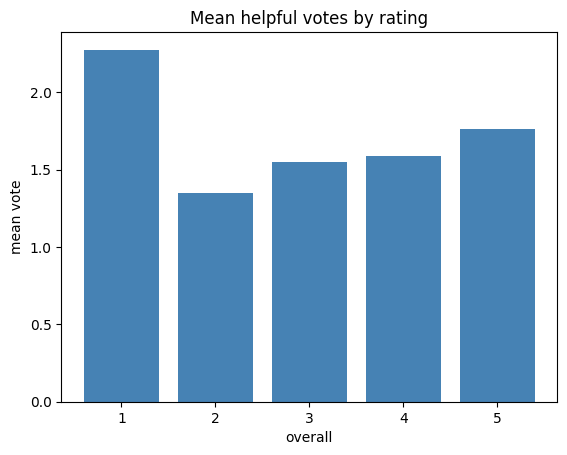

In [29]:
votes = df.groupby('overall')['vote'].agg(
    n_reviews='size',
    mean_vote='mean',
    share_with_vote=lambda v: (v > 0).mean(),
).round(3)
print(votes)

plt.bar(votes.index, votes['mean_vote'], color='steelblue')
plt.title('Mean helpful votes by rating')
plt.xlabel('overall')
plt.ylabel('mean vote')
plt.show()

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
نظرای 1 ستاره بیشترین رای مفید رو گرفتن: میانگین 2.28 در حالی که بقیه بین 1.35 تا 1.76 هستن.<br>
33 درصدشون حداقل 2 رای دارن. احتمالا چون مشکلای محصول رو میگن خریدارا مفیدتر میدوننشون.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>تحلیل 2: خریدار تایید شده یا نه</b>
</font></p>

          n_reviews  mean_overall  share
verified                                
False        117709         3.950  0.142
True         712681         4.032  0.858
overall       1      2      3      4      5
verified                                   
False     0.115  0.068  0.092  0.201  0.523
True      0.096  0.068  0.098  0.184  0.554


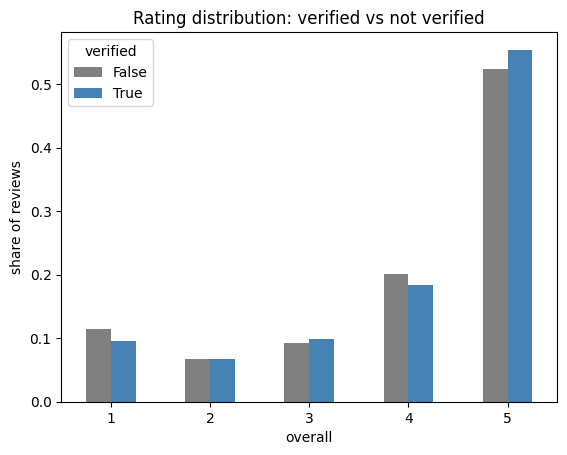

In [30]:
ver = df.groupby('verified')['overall'].agg(n_reviews='size', mean_overall='mean')
ver['share'] = ver['n_reviews'] / len(df)
print(ver.round(3))

dist = pd.crosstab(df['verified'], df['overall'], normalize='index').round(3)
print(dist)

dist.T.plot(kind='bar', color=['gray', 'steelblue'])
plt.title('Rating distribution: verified vs not verified')
plt.xlabel('overall')
plt.ylabel('share of reviews')
plt.legend(title='verified')
plt.xticks(rotation=0)
plt.show()

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
86 درصد نظرا تایید شده‌ان و میانگینشون 4.03 هست ولی بقیه 3.95.<br>
تاییدنشده‌ها یه کم بیشتر 1 ستاره میدن. فرقش کمه ولی verified تو تست هم هست و میشه به مدل داد.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>تحلیل 3: روند امتیاز تو زمان</b>
</font></p>

      n_reviews  mean_overall  share_5  share_negative
year                                                  
2016     464084         4.063    0.558           0.155
2017     262476         3.977    0.541           0.179
2018     103830         3.937    0.535           0.190
first month: 2016-01 | last month: 2018-10
date
2018-07    8888
2018-08    5710
2018-09    1910
2018-10      13
Freq: M, Name: n_reviews, dtype: int64


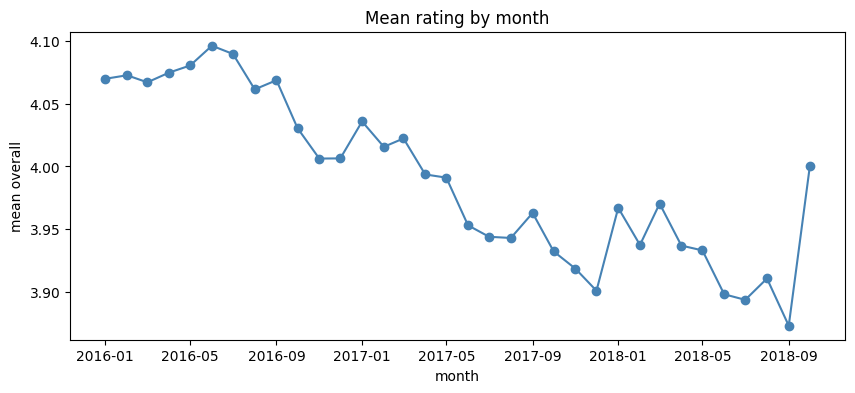

In [31]:
df['year'] = df['date'].dt.year

yearly = df.groupby('year')['overall'].agg(
    n_reviews='size',
    mean_overall='mean',
    share_5=lambda s: (s == 5).mean(),
    share_negative=lambda s: (s <= 2).mean(),
).round(3)
print(yearly)

monthly = df.groupby(df['date'].dt.to_period('M'))['overall'].agg(n_reviews='size', mean_overall='mean')
print('first month:', monthly.index.min(), '| last month:', monthly.index.max())
print(monthly['n_reviews'].tail(4))

plt.figure(figsize=(10, 4))
plt.plot(monthly.index.to_timestamp(), monthly['mean_overall'], marker='o', color='steelblue')
plt.title('Mean rating by month')
plt.xlabel('month')
plt.ylabel('mean overall')
plt.show()

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
میانگین از 4.06 تو 2016 رسیده به 3.94 تو 2018 و سهم نظرای منفی از 15.5 به 19 درصد رفته.<br>
تعداد نظرا هم کم شده و ماه آخر (اکتبر 2018) فقط 13 نظر داره پس نقطه آخر نمودار قابل اعتماد نیست.<br>
دلیلش معلوم نیست. شاید محصولای فروشگاه عوض شدن نه اینکه بدتر شده باشن.
</font></p>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=4>
<b>تحلیل 4: خلاصه نظرها</b>
</font></p>

In [32]:
s = df['summary'].str.lower().str.strip()

top_summary = df.groupby(s)['overall'].agg(n_reviews='size', mean_overall='mean').sort_values('n_reviews', ascending=False).head(15).round(2)
print(top_summary)

stars = s.str.extract(r'^(one|two|three|four|five) stars?$')[0]
print('summaries like "five stars":', stars.notna().sum())
print(pd.crosstab(stars, df['overall']))

                n_reviews  mean_overall
summary                                
great product        1510          4.89
works great          1358          4.87
works great!         1172          4.92
five stars            986          4.38
love it!              848          4.95
great product!        740          4.91
works well            705          4.59
love it               692          4.94
great                 671          4.87
great value           653          4.76
good product          620          4.55
perfect               600          4.97
great!                596          4.87
excellent             573          4.96
perfect!              511          4.99
summaries like "five stars": 1727
overall    1   2   3    4    5
0                             
five      87  44  49   30  793
four      24  11  16  124   24
one      146   9  17   28   42
three     24  12  72   16   34
two       17  63   4   20   21


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium"><font face="vazir" color="#0099cc" size=3>
خلاصه‌های پرتکرار جمله‌های کوتاه مثبتن مثل great product با میانگین نزدیک 5.<br>
خلاصه‌هایی مثل five stars عدد ستاره رو میگن و 69 درصدشون با امتیاز واقعی یکیه. پس summary به مدل بخش 3 کمک میکنه ولی کامل نیست.
</font></p>